In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_excel(r"C:\Users\nidap\Desktop\main project\PYTHON\AMAZON PRODUCT SALES ANALYSIS\Amazon sales.xlsx")
df.head(5)

,Order ID,Order Date,Ship Date,Status,Customer Name,Country,City,Region,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,On time,DarrinVanHuff,United States,Los Angeles,California,Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,Delay,BrosinaHoffman,United States,Los Angeles,California,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,Delay,BrosinaHoffman,United States,Los Angeles,California,Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,Delay,BrosinaHoffman,United States,Los Angeles,California,Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,Delay,BrosinaHoffman,United States,Los Angeles,California,Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825


In [4]:
df.shape

(3203, 13)

In [5]:
df.columns

Index(['Order ID', 'Order Date', 'Ship Date', 'Status', 'Customer Name',
       'Country', 'City', 'Region', 'Category', 'Product Name', 'Sales',
       'Quantity', 'Profit'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3203 entries, 0 to 3202
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       3203 non-null   object        
 1   Order Date     3203 non-null   datetime64[ns]
 2   Ship Date      3203 non-null   datetime64[ns]
 3   Status         3203 non-null   object        
 4   Customer Name  3203 non-null   object        
 5   Country        3203 non-null   object        
 6   City           3203 non-null   object        
 7   Region         3203 non-null   object        
 8   Category       3203 non-null   object        
 9   Product Name   3203 non-null   object        
 10  Sales          3203 non-null   float64       
 11  Quantity       3203 non-null   int64         
 12  Profit         3203 non-null   float64       
dtypes: datetime64[ns](2), float64(2), int64(1), object(8)
memory usage: 325.4+ KB


In [9]:
df.describe()

,Order Date,Ship Date,Sales,Quantity,Profit
count,3203,3203,3203.000000,3203.000000,3203.000000
mean,2013-05-10 03:06:07.530440192,2013-05-14 01:25:25.195129600,226.493233,3.828910,33.849032
min,2011-01-07 00:00:00,2011-01-09 00:00:00,0.990000,1.000000,-3399.980000
25%,2012-05-22 00:00:00,2012-05-26 00:00:00,19.440000,2.000000,3.852000
50%,2013-07-22 00:00:00,2013-07-25 00:00:00,60.840000,3.000000,11.166400
75%,2014-05-23 00:00:00,2014-05-27 00:00:00,215.809000,5.000000,33.000400
max,2014-12-31 00:00:00,2015-01-06 00:00:00,13999.960000,14.000000,6719.980800
std,NaN,NaN,524.876877,2.260947,174.109081


In [24]:
sales_array = np.array(df['Sales'])
quantity_array = np.array(df['Quantity'])
profit_array = np.array(df['Profit'])

In [ ]:
print("Average Sales:", np.mean(sales_array))
print("Median Sales:", np.median(sales_array))
print("Sales Standard Deviation:", np.std(sales_array, ddof=1))

print("Average Quantity:", np.mean(quantity_array))
print("Average Profit:", np.mean(profit_array))

In [26]:
print("Minimum Sales:", np.min(sales_array))
print("Maximum Sales:", np.max(sales_array))

print("Minimum Profit:", np.min(profit_array))
print("Maximum Profit:", np.max(profit_array))

Minimum Sales: 0.99
Maximum Sales: 13999.96
Minimum Profit: -3399.98
Maximum Profit: 6719.9808


In [27]:
print("25th Percentile:", np.percentile(sales_array, 25))
print("50th Percentile:", np.percentile(sales_array, 50))
print("75th Percentile:", np.percentile(sales_array, 75))

25th Percentile: 19.44
50th Percentile: 60.84
75th Percentile: 215.809


In [68]:
df['Order Size'] = np.where(df['Quantity'] >= 2, 'Large Order', 'Small Order')

df['Profit Status'] = np.where(df['Profit'] > 0,'Profit',
    np.where(df['Profit'] < 0, 'Loss', 'No Profit'))

df[['Quantity', 'Order Size', 'Profit', 'Profit Status']].head()

,Quantity,Order Size,Profit,Profit Status
0,2,Large Order,6.8714,Profit
1,7,Large Order,14.1694,Profit
2,4,Large Order,1.9656,Profit
3,4,Large Order,90.7152,Profit
4,3,Large Order,5.7825,Profit


In [29]:
df.dtypes

Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Status                   object
Customer Name            object
Country                  object
City                     object
Region                   object
Category                 object
Product Name             object
Sales                   float64
Quantity                  int64
Profit                  float64
Order Size               object
Profit Status            object
dtype: object

In [10]:
df.isnull().sum()

Order ID         0
Order Date       0
Ship Date        0
Status           0
Customer Name    0
Country          0
City             0
Region           0
Category         0
Product Name     0
Sales            0
Quantity         0
Profit           0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [67]:
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.month_name()
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)
df[['Order Date', 'Year', 'Month', 'Month Name', 'Year-Month']].head()

,Order Date,Year,Month,Month Name,Year-Month
0,2013-06-13,2013,6,June,2013-06
1,2011-06-09,2011,6,June,2011-06
2,2011-06-09,2011,6,June,2011-06
3,2011-06-09,2011,6,June,2011-06
4,2011-06-09,2011,6,June,2011-06


In [69]:
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df[['Order Date', 'Ship Date', 'Shipping Days']].head()

,Order Date,Ship Date,Shipping Days
0,2013-06-13,2013-06-17,4
1,2011-06-09,2011-06-14,5
2,2011-06-09,2011-06-14,5
3,2011-06-09,2011-06-14,5
4,2011-06-09,2011-06-14,5


In [70]:
df['Profit Margin'] = np.where(df['Sales'] != 0,
    (df['Profit'] / df['Sales']) * 100,0)
df[['Sales', 'Profit', 'Profit Margin']].head()

,Sales,Profit,Profit Margin
0,14.620,6.8714,47.00
1,48.860,14.1694,29.00
2,7.280,1.9656,27.00
3,907.152,90.7152,10.00
4,18.504,5.7825,31.25


In [71]:
df.head()

,Order ID,Order Date,Ship Date,Status,Customer Name,Country,City,Region,Category,Product Name,...,Quantity,Profit,Order Size,Profit Status,Year,Month,Month Name,Year-Month,Shipping Days,Profit Margin
0,CA-2013-138688,2013-06-13,2013-06-17,On time,DarrinVanHuff,United States,Los Angeles,California,Labels,Self-Adhesive Address Labels for Typewriters b...,...,2,6.8714,Large Order,Profit,2013,6,June,2013-06,4,47.00
1,CA-2011-115812,2011-06-09,2011-06-14,Delay,BrosinaHoffman,United States,Los Angeles,California,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,...,7,14.1694,Large Order,Profit,2011,6,June,2011-06,5,29.00
2,CA-2011-115812,2011-06-09,2011-06-14,Delay,BrosinaHoffman,United States,Los Angeles,California,Art,Newell 322,...,4,1.9656,Large Order,Profit,2011,6,June,2011-06,5,27.00
3,CA-2011-115812,2011-06-09,2011-06-14,Delay,BrosinaHoffman,United States,Los Angeles,California,Phones,Mitel 5320 IP Phone VoIP phone,...,4,90.7152,Large Order,Profit,2011,6,June,2011-06,5,10.00
4,CA-2011-115812,2011-06-09,2011-06-14,Delay,BrosinaHoffman,United States,Los Angeles,California,Binders,DXL Angle-View Binders with Locking Rings by S...,...,3,5.7825,Large Order,Profit,2011,6,June,2011-06,5,31.25


In [38]:
total_sales = df['Sales'].sum()
print("Total Sales:", round(total_sales, 2))

Total Sales: 725457.82


In [39]:
total_profit = df['Profit'].sum()
print("Total Profit:", round(total_profit, 2))

Total Profit: 108418.45


In [40]:
total_orders = df['Order ID'].nunique()
print("Total Orders:", total_orders)

Total Orders: 1611


In [41]:
total_quantity = df['Quantity'].sum()
print("Total Quantity:", total_quantity)

Total Quantity: 12264


In [42]:
total_customers = df['Customer Name'].nunique()
print("Total Customers:", total_customers)

Total Customers: 686


In [72]:
profit_margin = (total_profit / total_sales) * 100
print("Profit Margin:", round(profit_margin, 2), "%")

Profit Margin: 14.94 %


In [73]:
average_sales = df['Sales'].mean()
print("Average Sales:", round(average_sales, 2))

Average Sales: 226.49


In [6]:
category_analysis = df.groupby('Category')[['Sales', 'Profit', 'Quantity']].sum()
category_analysis = category_analysis.sort_values('Sales', ascending=False)
category_analysis

,Sales,Profit,Quantity
Category,,,
Chairs,101781.3280,4027.5843,734
Phones,98684.3520,9110.7426,1066
Tables,84754.5620,1482.6073,481
Storage,70532.8520,8645.3222,1039
Accessories,61114.1160,16484.5983,1032
Binders,55961.1130,16096.8016,1868
Copiers,49749.2420,19327.2351,88
Machines,42444.1220,-618.9264,147
Bookcases,36004.1235,-1646.5117,306


In [79]:
region_sales = df.groupby('Region')['Sales'].sum()
region_sales =region_sales.sort_values(ascending=False)
region_sales

Region
California    457687.6315
Washington    138641.2700
Arizona        35282.0010
Colorado       32108.1180
Oregon         17431.1500
Nevada         16729.1020
Utah           11220.0560
Montana         5589.3520
New Mexico      4783.5220
Idaho           4382.4860
Wyoming         1603.1360
Name: Sales, dtype: float64

In [7]:
city_sales = df.groupby('City')['Sales'].sum()
city_sales =city_sales.sort_values(ascending=False)
city_sales.head(10)

City
Los Angeles        175851.3410
Seattle            119540.7420
San Francisco      112669.0920
San Diego           47521.0290
Denver              12198.7930
Phoenix             11000.2570
North Las Vegas      9801.0020
Anaheim              7986.8700
Fresno               7888.5285
Sacramento           7311.2780
Name: Sales, dtype: float64

In [ ]:
product_sales = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False)
product_sales.head(10)

In [83]:
monthly_sales = df.groupby('Year-Month')['Sales'].sum()
monthly_sales

Year-Month
2011-01     2648.0570
2011-02     1348.6220
2011-03    11008.8980
2011-04     9343.4870
2011-05     6570.4380
2011-06     9629.4220
2011-07    21808.5530
2011-08    13248.2310
2011-09    14900.5370
2011-10     8728.7580
2011-11    23191.6245
2011-12    25456.4055
2012-01     6026.7360
2012-02     2004.9140
2012-03    15461.4120
2012-04     9056.0240
2012-05    12042.6555
2012-06     5088.9500
2012-07     7089.8260
2012-08    12548.3590
2012-09    13898.9240
2012-10    14016.6800
2012-11    14548.8960
2012-12    28182.8730
2013-01     3657.8220
2013-02     3100.1620
2013-03    17559.0310
2013-04    10370.1210
2013-05    10806.1350
2013-06    18598.0950
2013-07    14417.7550
2013-08    12680.9800
2013-09    23620.8765
2013-10    13135.3540
2013-11    26412.3450
2013-12    32617.3400
2014-01    12586.0040
2014-02     9814.9170
2014-03    28994.3980
2014-04    13196.9530
2014-05    15901.6460
2014-06    15203.0785
2014-07    21390.7600
2014-08    24196.7580
2014-09    29198.1230

In [8]:
status_analysis = df['Status'].value_counts()
status_analysis

Status
On time    1915
Delay      1288
Name: count, dtype: int64

In [87]:
loss_products = (df.groupby('Product Name')['Profit'].sum().sort_values())
loss_products.head(10)

Product Name
Lexmark MX611dhe Monochrome Laser Printer                            -3399.9800
Zebra GK420t Direct Thermal/Thermal Transfer Printer                  -938.2800
O'Sullivan 4-Shelf Bookcase in Odessa Pine                            -802.0974
Hon 2090 Â“Pillow SoftÂ” Series Mid Back Swivel/Tilt Chairs           -547.9110
Atlantic Metals Mobile 4-Shelf Bookcases, Custom Colors               -491.7150
Bestar Classic Bookcase                                               -439.9560
Chromcraft 48" x 96" Racetrack Double Pedestal Table                  -436.0704
Bretford Â“Just In TimeÂ” Height-Adjustable Multi-Task Work Tables    -425.7480
GBC DocuBind 300 Electric Binding Machine                             -399.7448
Panasonic KX MC6040 Color Laser Multifunction Printer                 -386.9570
Name: Profit, dtype: float64

In [ ]:
category_analysis['Sales'].plot.barh()
plt.title('Sales by Category')
plt.xlabel('Total Sales')
plt.ylabel('Category')
plt.show()

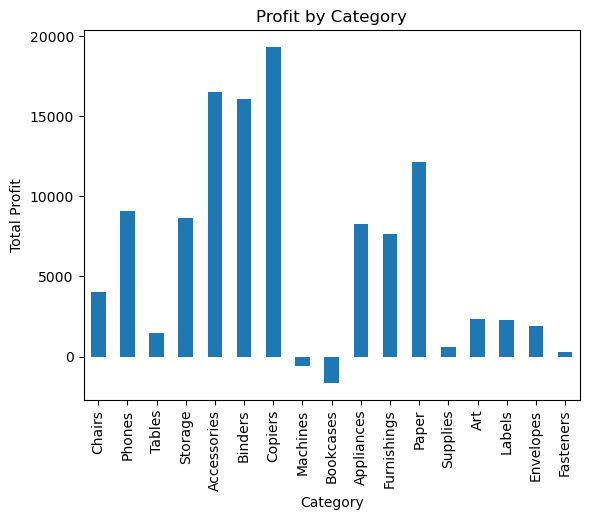

In [93]:
category_analysis['Profit'].plot.bar()
plt.title('Profit by Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.show()

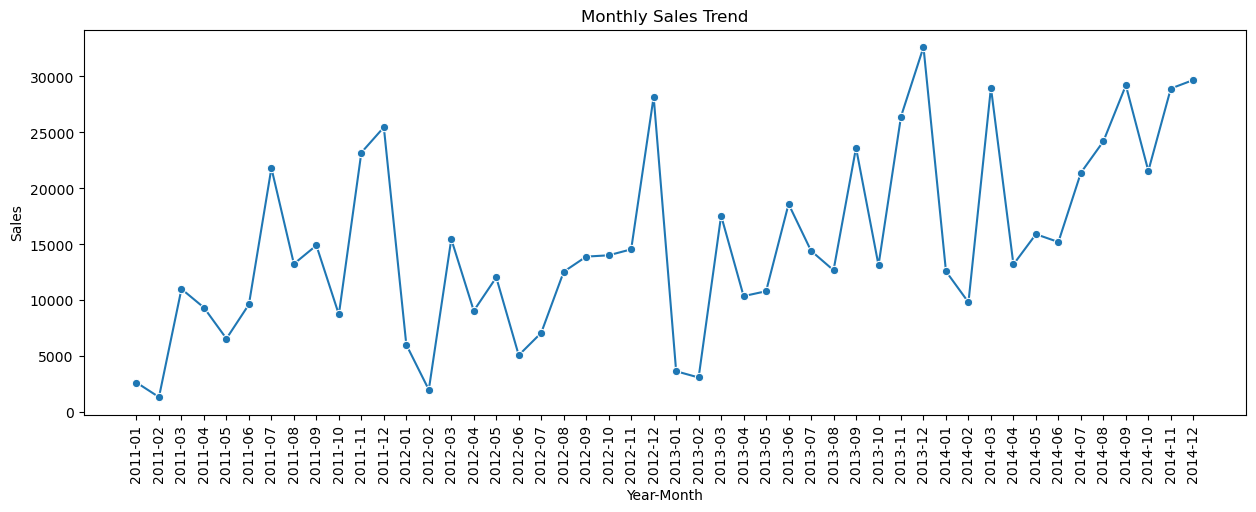

In [106]:
plt.figure(figsize=(15,5))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Year-Month')
plt.ylabel('Sales')
plt.xticks(rotation=90)
plt.show()

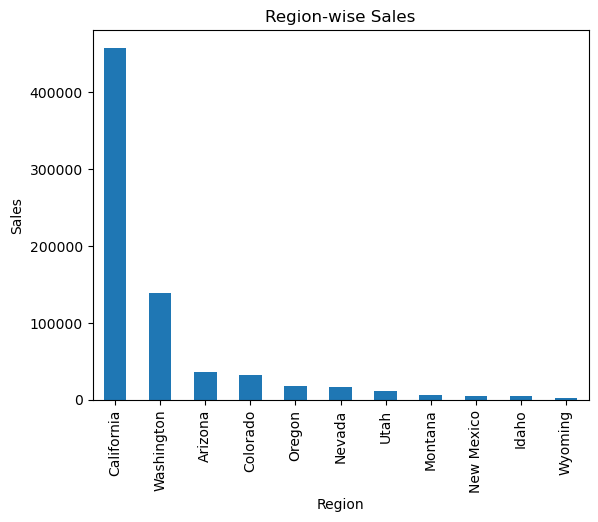

In [110]:
region_sales.plot.bar()
plt.title('Region-wise Sales')
plt.xlabel('Region')
plt.ylabel('Sales')
plt.show()

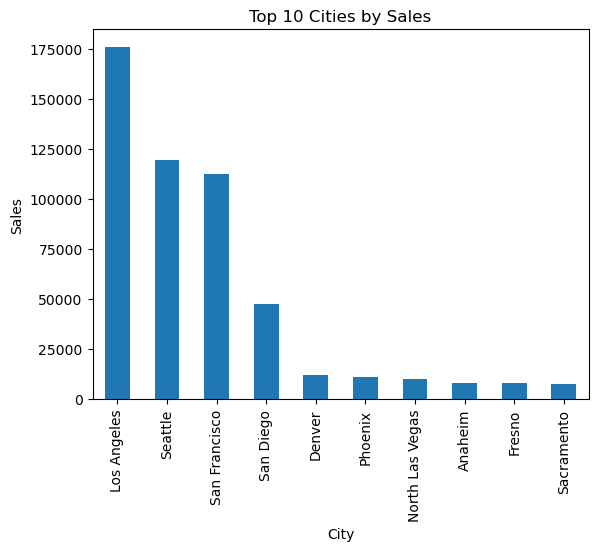

In [111]:
city_sales.head(10).plot.bar()
plt.title('Top 10 Cities by Sales')
plt.xlabel('City')
plt.ylabel('Sales')
plt.show()

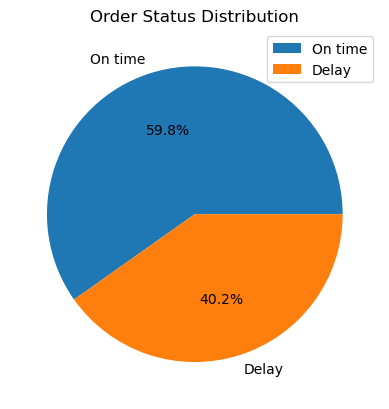

In [10]:
status_analysis.plot.pie(autopct='%1.1f%%')
plt.title('Order Status Distribution')
plt.ylabel('')
plt.legend()
plt.show()

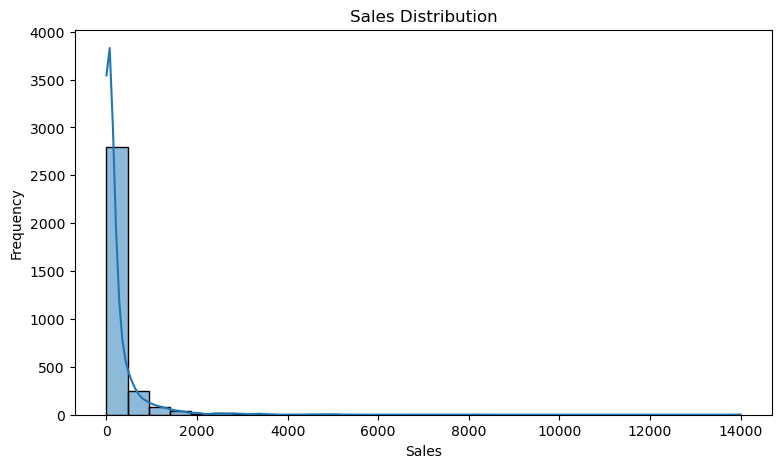

In [11]:
plt.figure(figsize=(9,5))
sns.histplot(df['Sales'], bins=30, kde=True)
plt.title('Sales Distribution')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()